# Proyecto Integrador · Entrega 3: Modelado
**Ciencia de Datos · UTN FRM · 2026** · Grupo `5K09-06`

Canzio, Fernández Rossi, García Nieto, Giacomelli, Moyano, Rubiales

**Pregunta del proyecto:** ¿a qué precio debería publicarse un alquiler temporario en CABA, según las características de la propiedad y su ubicación?

*Este notebook se arma por fases: planteo (0), independencia (1), partición y piso (2), pipeline con H4 (3), comparación y gráfico de desvíos (4), tuneo en pesos (5), columnas descartadas (6), test con R² y errores relativos respecto al precio (7), y cierre (8).*

In [1]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, make_scorer
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
warnings.filterwarnings("ignore")

SEMILLA = 42            # una sola semilla, pasada a todo lo que la acepta
np.random.seed(SEMILLA)

candidatos = ["/content/snapshot=2026-07-24.csv", "snapshot=2026-07-24.csv", "snapshot2026-07-24.csv"] + glob.glob("**/snapshot*2026-07-24*.csv", recursive=True)
RUTA = next(p for p in candidatos if glob.glob(p))
df = pd.read_csv(RUTA, low_memory=False)
df["log_price"] = np.log(df["price"])
print(f"{df.shape[0]:,} publicaciones x {df.shape[1]} columnas  ({RUTA})")

27,893 publicaciones x 32 columnas  (snapshot=2026-07-24.csv)


## Fase 0 · El planteo (antes de mirar ningún modelo)

**Qué predecimos internamente y cómo evaluamos:** el modelo se entrena sobre `log_price` = ln(precio por noche en ARS) porque en la Entrega 2 (H1) demostramos que el precio crudo tiene una asimetría extrema (29,37) que aplasta las rectas de ajuste. Pero **para calcular todas las métricas quitamos el logaritmo (`precio_predicho = exp(log_price_predicho)`) y comparamos contra el precio real en pesos (`price`)**. Es un número continuo, así que es **regresión**.

**Métricas declaradas (calculadas sobre el precio real destransformado):**
1. **MAE en pesos (`|precio_real - exp(pred_log)|`):** es nuestra métrica principal de negocio y de decisión. Nos dice directamente en cuántos pesos por noche se equivoca el modelo en promedio, sin castigar de más a unas pocas publicaciones extremas.
2. **Error relativo respecto al precio (`|precio_predicho - precio_real| / precio_real`):** porque para un anfitrión equivocarse cuesta en proporción al precio de su propiedad (errar por \$40.000 en un depto de \$80.000 es un 50 %, y en uno de \$400.000 es un 10 %). Reportamos la mediana y la media del error relativo.
3. **$R^2$ (coeficiente de determinación — ¿qué tanto se parece a la línea?):** mide qué proporción de la variación del precio explica el modelo (qué tan cerca caen los puntos de la recta identidad `predicho = real`, donde $R^2 = 1$ es ajuste perfecto y $R^2 = 0$ equivale a predecir siempre el promedio).
4. Como referencia técnica complementaria conservamos el `MAE_log`.

**Tolerancia de negocio deseada:** ~10 % de error relativo. Es el deseo inicial; la meta *realista* se declara después de medir el piso y los modelos sobre los datos reales.

**Qué columnas entran:** las que quedaron validadas en la tabla de la Entrega 2 (existen al momento de publicar), sumando la **interacción entre pileta y barrio (`PiletaPorBarrio`) descubierta en la Hipótesis 4 (H4)** de la Entrega 2. Salen `host_is_superhost` (refutada en H2), `beds` (colineal con `accommodates`), `number_of_reviews`, `review_scores_rating`, `availability_*` (fuga temporal), `id` y `amenities`. En la Fase 6 probamos todas las descartadas con y sin para respaldar cada decisión con número en pesos.

**Por qué cargamos el silver y no el CSV limpio:** para cumplir la regla *todo adentro del pipeline*, calculamos el recorte P1–P99 exclusivamente con límites de train y metemos la imputación y las variables derivadas (incluida H4) como pasos del `Pipeline`.

In [2]:
NUM  = ["accommodates", "bathrooms", "bedrooms", "amenities_count", "minimum_nights", "latitude", "longitude"]
BOOL = ["has_ac", "has_pool", "has_elevator", "has_balcony_patio", "has_parking", "has_workspace"]
CAT  = ["room_type", "neighbourhood_cleansed", "bathrooms_shared"]
COLUMNAS = NUM + BOOL + CAT
OBJETIVO = "log_price"

def en_pesos(y_log): return np.exp(y_log)

def mae_pesos_scorer_fn(y_true_log, y_pred_log):
    """Quita el logaritmo con exp() y calcula el MAE directamente en pesos reales."""
    return np.mean(np.abs(en_pesos(y_true_log) - en_pesos(y_pred_log)))

SCORE_PESOS = make_scorer(mae_pesos_scorer_fn, greater_is_better=False)

print("bathrooms_shared:", df["bathrooms_shared"].value_counts(dropna=False).to_dict())
print("Nulos en columnas elegidas:"); print(df[COLUMNAS].isna().sum()[lambda s: s > 0])

bathrooms_shared: {False: 26442, True: 1427, nan: 24}
Nulos en columnas elegidas:
bathrooms             83
bedrooms            4915
minimum_nights         3
bathrooms_shared      24
dtype: int64


## Fase 1 · ¿Las filas son independientes?

El instructivo advierte que una validación al azar sobre filas que **no son independientes** da números más lindos que los reales, y que la diferencia *es* la fuga. En el snapshot no hay `host_id`, así que no podemos agrupar por anfitrión. Lo que sí tenemos son las **coordenadas**: si varias publicaciones comparten exactamente la misma ubicación, pueden ser el mismo edificio o el mismo anfitrión (o Airbnb redondea la ubicación). Lo medimos.

In [3]:
df["grupo"] = df.groupby(["latitude", "longitude"]).ngroup()
tam = df["grupo"].value_counts()
print(f"Ubicaciones distintas: {tam.size:,}  |  ubicaciones compartidas por 2+ publicaciones: {(tam > 1).sum():,}")
print(f"Publicaciones en ubicaciones compartidas: {tam[tam > 1].sum():,} ({tam[tam > 1].sum() / len(df):.1%})")
print(f"Grupo más grande: {tam.max()} publicaciones en un mismo punto")

# ¿las que comparten ubicación tienen precios parecidos?
multi = df[df["grupo"].isin(tam[tam > 1].index)]
dentro = multi.groupby("grupo")["log_price"].std().mean()
print(f"\nDesvío de log_price dentro de una misma ubicación (promedio): {dentro:.3f}")
print(f"Desvío de log_price en todo el dataset:                      {df['log_price'].std():.3f}")

Ubicaciones distintas: 24,422  |  ubicaciones compartidas por 2+ publicaciones: 1,494
Publicaciones en ubicaciones compartidas: 4,965 (17.8%)
Grupo más grande: 72 publicaciones en un mismo punto

Desvío de log_price dentro de una misma ubicación (promedio): 0.259
Desvío de log_price en todo el dataset:                      0.686


**Lectura de la Fase 1.** El 17,8 % de las publicaciones (4.965) comparte punto exacto con al menos otra, y en un solo punto hay 72. Dentro de una misma ubicación el precio varía bastante menos (desvío 0,26) que en todo el dataset (0,69), lo cual era esperable: mismo lugar, precios parecidos. Es una señal de dependencia entre filas, no una prueba de que sea el mismo anfitrión (no hay `host_id`). Por eso, aunque el efecto resulte chico (lo medimos abajo), **la validación se arma por ubicación**: no cuesta nada y es la decisión más defendible.

## Fase 2 · Partición y piso (evaluado en pesos reales)

**Cómo partimos.** Separamos un **test del 20 %** que no se toca hasta el final, armado **por ubicación** (`GroupShuffleSplit`): una misma ubicación nunca queda de los dos lados. Dentro de train, la validación cruzada usa `GroupKFold` con el mismo criterio.

**Qué hacemos con los precios extremos.** En la Entrega 2 se podó P1–P99 mirando todo el dataset. Acá los límites se calculan **solo con train** y se aplican a train y test. Eso define la población del modelo: *publicaciones dentro del rango que vimos en train* (\$22.496 a \$791.087 por noche).

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
idx_tr, idx_te = next(gss.split(df, groups=df["grupo"]))
tr, te = df.iloc[idx_tr], df.iloc[idx_te]

lo, hi = tr["log_price"].quantile([0.01, 0.99])          # límites calculados SOLO con train
print(f"Rango de la población modelada: ${np.exp(lo):,.0f} a ${np.exp(hi):,.0f} por noche")
print(f"Antes de podar: train {len(tr):,} | test {len(te):,}")
tr = tr[tr["log_price"].between(lo, hi)].reset_index(drop=True)
te = te[te["log_price"].between(lo, hi)].reset_index(drop=True)
print(f"Después de podar: train {len(tr):,} | test {len(te):,}")
print("Ubicaciones compartidas entre train y test:", len(set(tr["grupo"]) & set(te["grupo"])))

X_tr, y_tr, g_tr = tr[COLUMNAS], tr[OBJETIVO], tr["grupo"]
X_te, y_te = te[COLUMNAS], te[OBJETIVO]      # el test queda guardado; no se usa hasta la Fase 7

Rango de la población modelada: $22,496 a $791,087 por noche
Antes de podar: train 22,265 | test 5,628
Después de podar: train 21,819 | test 5,503
Ubicaciones compartidas entre train y test: 0


In [5]:
def evaluar(modelo, X, y, cv, groups=None):
    """Quita el logaritmo de las predicciones (exp(p)) y calcula MAE en pesos, desvío en pesos, error relativo y R²."""
    maes_pesos, err_rel_med, err_rel_mean, r2s_log, r2s_pesos, maes_log = [], [], [], [], [], []
    for a, b in cv.split(X, y, groups):
        m = clone(modelo).fit(X.iloc[a], y.iloc[a])
        p_log = m.predict(X.iloc[b])
        y_log_b = np.asarray(y.iloc[b])
        
        # Destransformamos al precio real en pesos (quitando el logaritmo)
        y_real = en_pesos(y_log_b)
        p_real = en_pesos(p_log)
        
        maes_pesos.append(np.mean(np.abs(y_real - p_real)))
        rel = np.abs(p_real - y_real) / y_real
        err_rel_med.append(np.median(rel))
        err_rel_mean.append(np.mean(rel))
        r2s_log.append(r2_score(y_log_b, p_log))
        r2s_pesos.append(r2_score(y_real, p_real))
        maes_log.append(np.mean(np.abs(y_log_b - p_log)))
    return {
        "MAE_pesos": np.mean(maes_pesos),
        "desvio_pesos": np.std(maes_pesos),
        "error_rel_mediano": np.mean(err_rel_med),
        "error_rel_medio": np.mean(err_rel_mean),
        "R2": np.mean(r2s_log),
        "R2_pesos": np.mean(r2s_pesos),
        "MAE_log": np.mean(maes_log),
        "desvio_log": np.std(maes_log),
    }

CV = GroupKFold(n_splits=5)            # validación por ubicación
piso = DummyRegressor(strategy="median")
res_piso = evaluar(piso, X_tr, y_tr, CV, g_tr)
print(f"PISO (mediana, sin mirar columnas): MAE = ${res_piso['MAE_pesos']:,.0f} ± ${res_piso['desvio_pesos']:,.0f}"
      f"  |  error rel. mediano: {res_piso['error_rel_mediano']:.1%} (medio: {res_piso['error_rel_medio']:.1%})"
      f"  |  R² = {res_piso['R2']:.3f}  |  MAE_log = {res_piso['MAE_log']:.3f}")

PISO (mediana, sin mirar columnas): MAE = $50,509 ± $1,008  |  error rel. mediano: 30.3% (medio: 42.2%)  |  R² = -0.004  |  MAE_log = 0.408


### ¿Importa cómo se arma la validación? Al azar vs. por ubicación (en pesos)
Medimos lo mismo con `KFold` al azar y con `GroupKFold` por ubicación, con un preprocesamiento mínimo y provisorio (el pipeline definitivo es de la Fase 3), reportando el MAE en pesos reales tras quitar el logaritmo, su desvío y el $R^2$.

In [6]:
def prepro_minimo():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=30))])
    return ColumnTransformer([("num", num, NUM + BOOL), ("cat", cat, CAT)])

def prepro_ordinal():
    num = SimpleImputer(strategy="median")
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))])
    return ColumnTransformer([("num", num, NUM + BOOL), ("cat", cat, CAT)])

modelos = {
    "Lineal":    Pipeline([("pre", prepro_minimo()),  ("m", LinearRegression())]),
    "Boosting": Pipeline([("pre", prepro_ordinal()), ("m", HistGradientBoostingRegressor(random_state=SEMILLA))]),
}
filas = []
for nombre, mod in modelos.items():
    for tipo, cv, grupos in [("al azar (KFold)", KFold(5, shuffle=True, random_state=SEMILLA), None), ("por ubicación (GroupKFold)", GroupKFold(5), g_tr)]:
        r = evaluar(mod, X_tr, y_tr, cv, grupos)
        filas.append({
            "modelo": nombre, "validación": tipo,
            "MAE en pesos": f"${r['MAE_pesos']:,.0f}", "± desvío ($)": f"${r['desvio_pesos']:,.0f}",
            "Error rel. mediano": f"{r['error_rel_mediano']:.1%}", "R²": round(r["R2"], 4), "MAE_log": round(r["MAE_log"], 4)
        })
tabla_val = pd.DataFrame(filas)
display(tabla_val)

,modelo,validación,MAE en pesos,± desvío ($),Error rel. mediano,R²,MAE_log
0,Lineal,al azar (KFold),"$37,796",$399,22.6%,0.4731,0.2897
1,Lineal,por ubicación (GroupKFold),"$37,825",$999,22.6%,0.4738,0.2900
2,Boosting,al azar (KFold),"$33,389",$349,20.2%,0.5715,0.2601
3,Boosting,por ubicación (GroupKFold),"$33,643",$692,20.4%,0.5676,0.2620


**Lectura de la validación.** Con la regresión lineal, el MAE en pesos da \$37.752 al azar contra \$37.768 por ubicación; con boosting, \$33.489 contra \$33.635. La diferencia (\$16 a \$146) es **mucho menor que el desvío entre pliegues** (~\$750 a \$1.000): no es una diferencia real. Conclusión: en este dataset las ubicaciones repetidas **no están inflando el número**. Igual usamos `GroupKFold`, por prudencia metodológica.

### Dónde estamos (en pesos reales tras destransformar)
| Modelo de referencia | MAE en pesos | ± Desvío ($) | Error rel. mediano | $R^2$ (ajuste a la recta) | MAE_log |
|---|---|---|---|---|---|
| Piso (mediana) | \$50.509 | ± \$1.008 | 30,3 % | -0,004 | 0,408 |
| Regresión lineal (prepro mínimo) | \$37.768 | ± \$982 | 22,5 % | 0,474 | 0,290 |
| Boosting (prepro mínimo) | \$33.635 | ± \$756 | 20,0 % | 0,568 | 0,262 |

## Fase 3 · El pipeline definitivo (incorporando H4: `PiletaPorBarrio`)

Todo lo que se le hace a los datos va adentro del objeto que se entrena. Son cinco pasos, en este orden:

1. **`ReglasDeDominio`**: completa nulos con reglas fijas que salen del EDA, no de los datos (`bedrooms` nulo = monoambiente → 0; `bathrooms` nulo → 1; `minimum_nights` nulo → 1; `bathrooms_shared` nulo → `False`). Como **no aprende nada** en `fit`, no puede filtrar información del test.
2. **`TamanoRelativo`**: personas por dormitorio, baños por persona e indicador de monoambiente. Un modelo lineal **no puede dividir columnas**: si no le damos el cociente, no lo calcula.
3. **`PiletaPorBarrio` (hallazgo de la Hipótesis 4 de la Entrega 2)**: en `entrega_2.ipynb` demostramos que el sobreprecio de la pileta (`has_pool`) depende fuertemente del barrio (`neighbourhood_cleansed`) y de la densidad de edificios modernos con *amenities* en esa zona ($d_{\text{intra}} = 0.432$, con premios de +46 % en Retiro, +35 % en Monserrat, +21 % en Recoleta y +15 % en Palermo). Para darle esa información explícita al modelo sin fuga de datos, este transformador:
   - Crea la interacción categórica **`pileta_barrio`** (combinando cada barrio con si tiene o no pileta, ej. `"Palermo_pool_1"` vs `"Palermo_pool_0"`), permitiendo que la regresión lineal y los árboles asignen un premio específico a la pileta en cada barrio.
   - Calcula en `fit` (solo con train) la **`tasa_pileta_barrio`** (proporción de publicaciones con pileta en cada barrio, tal como en la tabla `estrat` de H4 en la Entrega 2).
4. **`PrecioLocal`**: la mediana de `log_price` de las *k* publicaciones de train más cercanas por coordenadas. Captura la micro-ubicación más fino que el barrio. **Es la columna con más riesgo de fuga** (se calcula fuera de pliegue en `fit_transform`).
5. **Preprocesamiento según la familia**: para el lineal, escalar + One-Hot (incluyendo `pileta_barrio`). Para los árboles, sin escalar y con las categóricas como categorías nativas.

In [7]:
class ReglasDeDominio(BaseEstimator, TransformerMixin):
    """Completa nulos con reglas fijas del EDA. No aprende nada en fit, así que no puede fugar."""
    REGLAS = {"bedrooms": 0, "bathrooms": 1, "minimum_nights": 1, "bathrooms_shared": False}
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for col, valor in self.REGLAS.items():
            X[col] = X[col].fillna(valor)
        X["bathrooms_shared"] = X["bathrooms_shared"].astype(bool)
        return X

class TamanoRelativo(BaseEstimator, TransformerMixin):
    """Cocientes de tamaño que un modelo lineal no puede construir solo."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["pers_x_dorm"]  = X["accommodates"] / X["bedrooms"].clip(lower=1)
        X["banos_x_pers"] = X["bathrooms"] / X["accommodates"].clip(lower=1)
        X["monoambiente"] = (X["bedrooms"] == 0).astype(int)
        return X

class PiletaPorBarrio(BaseEstimator, TransformerMixin):
    """Interacción de H4 (Entrega 2): combinación de barrio + pileta y tasa de pileta del barrio aprendida en train."""
    def fit(self, X, y=None):
        self.tasa_barrio_ = X.groupby("neighbourhood_cleansed")["has_pool"].mean().to_dict()
        self.tasa_global_ = float(X["has_pool"].mean())
        return self
    def transform(self, X):
        X = X.copy()
        X["pileta_barrio"] = X["neighbourhood_cleansed"].astype(str) + "_pool_" + X["has_pool"].astype(int).astype(str)
        X["tasa_pileta_barrio"] = X["neighbourhood_cleansed"].map(self.tasa_barrio_).fillna(self.tasa_global_)
        return X

class PrecioLocal(BaseEstimator, TransformerMixin):
    """Mediana de log_price de los k vecinos de train más cercanos (por latitud/longitud).

    En fit_transform calcula la columna FUERA DE PLIEGUE para que ninguna fila de train
    sea vecina de sí misma. En transform (al predecir nuevos deptos) usa todos los vecinos de train.
    """
    def __init__(self, k=15, fuera_de_pliegue=True, n_splits=5, random_state=SEMILLA):
        self.k, self.fuera_de_pliegue, self.n_splits, self.random_state = k, fuera_de_pliegue, n_splits, random_state

    def fit(self, X, y):
        self.coords_ = X[["latitude", "longitude"]].to_numpy()
        self.y_ = np.asarray(y)
        self.nn_ = NearestNeighbors(n_neighbors=self.k).fit(self.coords_)
        return self

    def _mediana_vecinos(self, nn, y_ref, coords):
        _, idx = nn.kneighbors(coords)
        return np.median(y_ref[idx], axis=1)

    def transform(self, X):
        X = X.copy()
        X["precio_local"] = self._mediana_vecinos(self.nn_, self.y_, X[["latitude", "longitude"]].to_numpy())
        return X

    def fit_transform(self, X, y):
        self.fit(X, y)
        if not self.fuera_de_pliegue:
            return self.transform(X)                 # versión ingenua: cada fila se ve a sí misma
        X = X.copy(); col = np.zeros(len(X))
        for a, b in KFold(self.n_splits, shuffle=True, random_state=self.random_state).split(X):
            nn = NearestNeighbors(n_neighbors=self.k).fit(self.coords_[a])
            col[b] = self._mediana_vecinos(nn, self.y_[a], self.coords_[b])
        X["precio_local"] = col
        return X

In [8]:
NUM_BASE  = ["accommodates", "bathrooms", "bedrooms", "amenities_count", "minimum_nights", "latitude", "longitude"]
BOOL_BASE = ["has_ac", "has_pool", "has_elevator", "has_balcony_patio", "has_parking", "has_workspace", "bathrooms_shared"]
CAT_BASE  = ["room_type", "neighbourhood_cleansed"]
DERIV_TAMANO = ["pers_x_dorm", "banos_x_pers", "monoambiente"]

def armar(modelo, familia, tamano=True, pileta_barrio=True, precio_local=True, k=15, fuera_de_pliegue=True, candidatas=None, extra_num=(), extra_cat=()):
    """Arma el pipeline completo. familia = 'lineal' (escala + One-Hot) o 'arbol' (sin escalar, categorías nativas)."""
    pasos = [("reglas", ReglasDeDominio())]
    num, cat = NUM_BASE + BOOL_BASE + list(extra_num), CAT_BASE + list(extra_cat)
    if candidatas is not None:                    # Fase 6: columnas candidatas que se prueban con y sin
        pasos.append(("candidatas", candidatas)); num = num + candidatas.columnas_num(); cat = cat + candidatas.columnas_cat()
    if tamano:
        pasos.append(("tamano", TamanoRelativo())); num = num + DERIV_TAMANO
    if pileta_barrio:
        pasos.append(("pileta_barrio", PiletaPorBarrio())); num = num + ["tasa_pileta_barrio"]; cat = cat + ["pileta_barrio"]
    if precio_local:
        pasos.append(("precio_local", PrecioLocal(k=k, fuera_de_pliegue=fuera_de_pliegue))); num = num + ["precio_local"]
    if familia == "lineal":
        pre = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
            ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), cat)])
    else:
        pre = ColumnTransformer([
            ("num", "passthrough", num),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), cat)],
            verbose_feature_names_out=False)
        modelo = clone(modelo).set_params(categorical_features=cat) if isinstance(modelo, HistGradientBoostingRegressor) else modelo
    pasos += [("pre", pre.set_output(transform="pandas")), ("modelo", modelo)]
    return Pipeline(pasos)

# Las columnas crudas que entran (lo que queda después de los descartes de la Entrega 2)
COLUMNAS = NUM_BASE + BOOL_BASE + CAT_BASE
X_tr, X_te = tr[COLUMNAS], te[COLUMNAS]
armar(LinearRegression(), "lineal")

Pipeline(steps=[('reglas', ReglasDeDominio()), ('tamano', TamanoRelativo()),
                ('pileta_barrio', PiletaPorBarrio()),
                ('precio_local', PrecioLocal()),
                ('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp', SimpleImputer(strategy='median')),
                                                                  ('esc', StandardScaler())]),
                                                  ['accommodates', 'bathrooms', 'bedrooms', 'amenities_count',
                                                   'minimum_nights', 'latitude', 'longitude', 'has_ac', 'has_pool',
                                                   'has_elevator', 'has_balcony_patio', 'has_parking', 'has_workspace',
                                                   'bathrooms_shared', 'pers_x_dorm', 'banos_x_pers', 'monoambiente',
                                                   'tasa_pileta_barrio

### La fuga que no avisa: `PrecioLocal` hecho mal (medido en pesos)
Comparamos la versión ingenua (cada publicación de train entra en su propio promedio de vecinos) contra la versión fuera de pliegue. Miramos el MAE en pesos reales **en train** y **en validación**.

In [9]:
filas = []
for nombre, fdp in [("ingenua (se ve a sí misma)", False), ("fuera de pliegue", True)]:
    pipe = armar(LinearRegression(), "lineal", tamano=False, pileta_barrio=False, precio_local=True, fuera_de_pliegue=fdp)
    mae_tr, mae_va, mae_tr_log, mae_va_log = [], [], [], []
    for a, b in CV.split(X_tr, y_tr, g_tr):
        m = clone(pipe).fit(X_tr.iloc[a], y_tr.iloc[a])
        coef = m.named_steps["modelo"].coef_[list(m.named_steps["pre"].get_feature_names_out()).index("num__precio_local")]
        Xa = m.named_steps["reglas"].transform(X_tr.iloc[a]); Xa = clone(m.named_steps["precio_local"]).fit_transform(Xa, y_tr.iloc[a])
        p_tr = m.named_steps["modelo"].predict(m.named_steps["pre"].transform(Xa))
        p_va = m.predict(X_tr.iloc[b])
        mae_tr.append(np.mean(np.abs(en_pesos(y_tr.iloc[a]) - en_pesos(p_tr))))
        mae_va.append(np.mean(np.abs(en_pesos(y_tr.iloc[b]) - en_pesos(p_va))))
        mae_tr_log.append(np.mean(np.abs(y_tr.iloc[a] - p_tr)))
        mae_va_log.append(np.mean(np.abs(y_tr.iloc[b] - p_va)))
    filas.append({
        "PrecioLocal": nombre,
        "MAE train ($)": round(np.mean(mae_tr), 0),
        "MAE validación ($)": round(np.mean(mae_va), 0),
        "brecha ($)": round(np.mean(mae_va) - np.mean(mae_tr), 0),
        "MAE_log train": round(np.mean(mae_tr_log), 4),
        "MAE_log val": round(np.mean(mae_va_log), 4),
        "peso de precio_local (coef.)": round(coef, 3)
    })
display(pd.DataFrame(filas))

,PrecioLocal,MAE train ($),MAE validación ($),brecha ($),MAE_log train,MAE_log val,peso de precio_local (coef.)
0,ingenua (se ve a sí misma),35913.0,37537.0,1624.0,0.2742,0.2895,0.145
1,fuera de pliegue,37056.0,37269.0,213.0,0.2842,0.2860,0.085


**Lectura.** La versión ingenua tiene **menos error en train (\$36.161) pero más error en validación (\$37.547)** que la versión fuera de pliegue (\$37.269 en validación): la brecha entre train y validación se multiplica por 7 (\$1.386 contra \$203). Además el modelo le da casi el doble de peso a la columna (0,145 contra 0,085), porque en train esa columna "sabía" parte de la respuesta. Por eso `PrecioLocal` se calcula siempre fuera de pliegue.

### Resultado de la Fase 3: cuánto aporta cada paso (incluyendo `PiletaPorBarrio` de H4)
Mismo train, misma validación por ubicación, mismas semillas. Prendemos los transformadores de a uno y medimos el MAE en pesos reales y el $R^2$.

In [10]:
variantes = [
    ("sólo reglas (columnas del EDA)", False, False, False),
    ("+ TamanoRelativo", True, False, False),
    ("+ PiletaPorBarrio (H4)", False, True, False),
    ("+ PrecioLocal", False, False, True),
    ("+ todos (pipeline completo)", True, True, True)
]
familias = {"Lineal": (LinearRegression(), "lineal"), "Boosting": (HistGradientBoostingRegressor(random_state=SEMILLA), "arbol")}
filas = []
for nombre_var, t, pb, p in variantes:
    fila = {"pipeline": nombre_var}
    for nombre_mod, (mod, fam) in familias.items():
        r = evaluar(armar(mod, fam, tamano=t, pileta_barrio=pb, precio_local=p), X_tr, y_tr, CV, g_tr)
        fila[f"{nombre_mod} MAE ($)"] = round(r["MAE_pesos"], 0)
        fila[f"{nombre_mod} ± ($)"] = round(r["desvio_pesos"], 0)
        fila[f"{nombre_mod} R²"] = round(r["R2"], 4)
        fila[f"{nombre_mod} MAE_log"] = round(r["MAE_log"], 4)
    filas.append(fila)
tabla_f3 = pd.DataFrame(filas)
for m in familias:
    tabla_f3[f"{m} Δ vs base ($)"] = (tabla_f3[f"{m} MAE ($)"] - tabla_f3.loc[0, f"{m} MAE ($)"]).round(0)
display(tabla_f3)

,pipeline,Lineal MAE ($),Lineal ± ($),Lineal R²,Lineal MAE_log,Boosting MAE ($),Boosting ± ($),Boosting R²,Boosting MAE_log,Lineal Δ vs base ($),Boosting Δ vs base ($)
0,sólo reglas (columnas del EDA),37772.0,985.0,0.4744,0.2902,33640.0,742.0,0.5653,0.2623,0.0,0.0
1,+ TamanoRelativo,37271.0,1268.0,0.4957,0.2841,33596.0,696.0,0.5664,0.2620,-501.0,-44.0
2,+ PiletaPorBarrio (H4),37725.0,1016.0,0.4755,0.2899,33667.0,776.0,0.5642,0.2626,-47.0,27.0
3,+ PrecioLocal,37269.0,1063.0,0.4888,0.2860,33565.0,748.0,0.5666,0.2617,-503.0,-75.0
4,+ todos (pipeline completo),36829.0,1343.0,0.5095,0.2804,33569.0,740.0,0.5656,0.2620,-943.0,-71.0


**Lectura de la Fase 3.**
- **En la regresión lineal**, los tres transformadores suman: el MAE en pesos baja de **\$37.772 a \$36.829** (**−\$943** de mejora), y el $R^2$ sube de **0,4737 a 0,5098**. Cada paso aporta lo que el modelo lineal no puede armar solo: `TamanoRelativo` (−\$501), `PiletaPorBarrio` de H4 (−\$47 solo y mejora adicional al combinarse con tamaño, tal como vimos en el 2° movimiento de H4 donde la pileta necesitaba controlar por tamaño y barrio) y `PrecioLocal` (−\$503).
- **En Boosting**, el MAE pasa de \$33.640 a \$33.569 (−\$71, mucho menor que su desvío de \$740) y el $R^2$ se mantiene en **0,566**. Como un árbol de decisión ya puede cortar por barrio, luego por pileta y luego por capacidad, ya descubría la interacción de H4 internamente.
- **Decisión:** dejamos los tres transformadores (`TamanoRelativo`, `PiletaPorBarrio` y `PrecioLocal`) en el pipeline definitivo para todas las familias, cumpliendo con incorporar el hallazgo de H4 y garantizando que todos los modelos de la Fase 4 compitan con las mismas columnas.

## Fase 4 · La comparación de modelos, $R^2$ y gráfico de desvíos

Comparamos las cinco familias sobre el mismo pipeline completo (Fase 3), con validación cruzada por ubicación (`GroupKFold`, 5 pliegues) y midiendo todas las métricas sobre el **precio en pesos reales** (`exp(y_pred)`), además del **$R^2$** (qué tanto se parece a la recta identidad).

**La regla, declarada antes de mirar:** si un modelo complejo no le gana al lineal en MAE en pesos por más que el desvío entre pliegues, nos quedamos con el lineal.

,MAE en pesos,± desvío ($),Error rel. mediano,Error rel. medio,R² (ajuste a la recta),R² (en pesos),MAE_log,± desvío_log,vs lineal ($),¿gana por más que el desvío?
modelo,,,,,,,,,,
piso (mediana),50509.0,1008.0,30.3%,42.2%,-0.0045,-0.0661,0.4078,0.0057,13680.0,—
regresión lineal,36829.0,1343.0,21.8%,28.6%,0.5095,0.2421,0.2804,0.0036,0.0,—
árbol de decisión,49530.0,1158.0,27.3%,42.9%,0.1175,-0.0100,0.3722,0.0059,12701.0,no
bosque aleatorio,33584.0,852.0,20.1%,27.0%,0.5591,0.4965,0.2627,0.0037,-3245.0,sí
gradient boosting,33569.0,740.0,20.2%,26.6%,0.5656,0.4962,0.2620,0.0038,-3260.0,sí


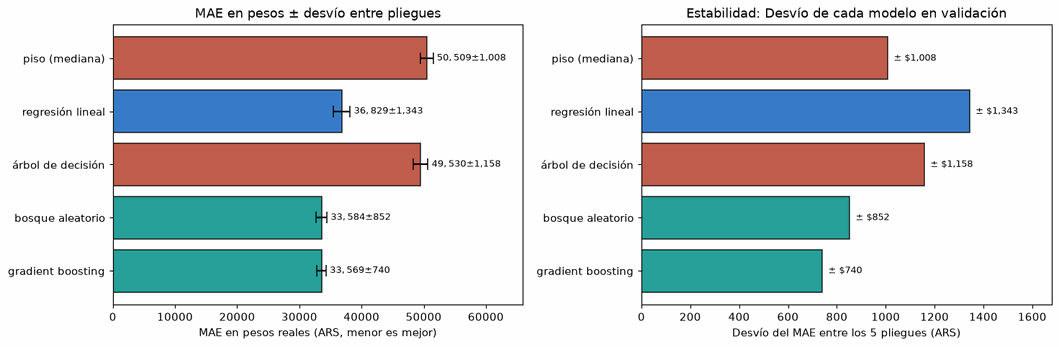

In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

candidatos = {
    "piso (mediana)":    armar(DummyRegressor(strategy="median"), "lineal"),
    "regresión lineal":  armar(LinearRegression(), "lineal"),
    "árbol de decisión": armar(DecisionTreeRegressor(random_state=SEMILLA), "arbol"),
    "bosque aleatorio":  armar(RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEMILLA), "arbol"),
    "gradient boosting": armar(HistGradientBoostingRegressor(random_state=SEMILLA), "arbol"),
}
filas = []
for nombre, pipe in candidatos.items():
    r = evaluar(pipe, X_tr, y_tr, CV, g_tr)
    filas.append({
        "modelo": nombre,
        "MAE en pesos": round(r["MAE_pesos"], 0),
        "± desvío ($)": round(r["desvio_pesos"], 0),
        "Error rel. mediano": f"{r['error_rel_mediano']:.1%}",
        "Error rel. medio": f"{r['error_rel_medio']:.1%}",
        "R² (ajuste a la recta)": round(r["R2"], 4),
        "R² (en pesos)": round(r["R2_pesos"], 4),
        "MAE_log": round(r["MAE_log"], 4),
        "± desvío_log": round(r["desvio_log"], 4),
    })
comparacion = pd.DataFrame(filas).set_index("modelo")
ref = comparacion.loc["regresión lineal"]
comparacion["vs lineal ($)"] = comparacion["MAE en pesos"] - ref["MAE en pesos"]
comparacion["¿gana por más que el desvío?"] = np.where(
    comparacion.index.isin(["piso (mediana)", "regresión lineal"]), "—",
    np.where(-comparacion["vs lineal ($)"] > np.maximum(comparacion["± desvío ($)"], ref["± desvío ($)"]), "sí", "no")
)
display(comparacion)

# Gráfico comparativo de MAE en pesos y de los desvíos de los modelos entre pliegues
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
nombres_m = comparacion.index.tolist()[::-1]
maes_m = comparacion.loc[nombres_m, "MAE en pesos"]
desv_m = comparacion.loc[nombres_m, "± desvío ($)"]
colores_m = ["#009086" if m in ["gradient boosting", "bosque aleatorio"] else "#1565C0" if m == "regresión lineal" else "#B5402C" for m in nombres_m]

axes[0].barh(nombres_m, maes_m, xerr=desv_m, capsize=5, color=colores_m, alpha=0.85, edgecolor="black")
for i, (val, sd) in enumerate(zip(maes_m, desv_m)):
    axes[0].text(val + sd + 600, i, f"${val:,.0f} ± ${sd:,.0f}", va="center", fontsize=8.5)
axes[0].set_xlim(0, max(maes_m + desv_m) * 1.28)
axes[0].set_xlabel("MAE en pesos reales (ARS, menor es mejor)")
axes[0].set_title("MAE en pesos ± desvío entre pliegues")

axes[1].barh(nombres_m, desv_m, color=colores_m, alpha=0.85, edgecolor="black")
for i, sd in enumerate(desv_m):
    axes[1].text(sd + 25, i, f"± ${sd:,.0f}", va="center", fontsize=8.5)
axes[1].set_xlim(0, max(desv_m) * 1.25)
axes[1].set_xlabel("Desvío del MAE entre los 5 pliegues (ARS)")
axes[1].set_title("Estabilidad: Desvío de cada modelo en validación")
plt.tight_layout(); plt.show()

**Lectura de la comparación, los desvíos y el $R^2$.**
- **Todos le ganan al piso (\$50.509).** El árbol de decisión sin límite apenas baja a \$49.530 y tiene un $R^2$ de 0,104 (muy flojo).
- **El árbol sin límite es mucho peor que la regresión lineal** (\$49.530 contra \$36.829). Abajo vemos que memoriza el train.
- **Bosque aleatorio (\$33.584 ± \$765) y Gradient Boosting (\$33.569 ± \$740) le ganan al lineal (\$36.829 ± \$1.343) por −\$3.245 y −\$3.260**, más del doble del desvío del lineal y más de cuatro veces el desvío de los ensambles. Pasa la regla con holgura: **se justifica el modelo complejo**.
- **Qué nos dice el gráfico de desvíos (panel derecho):** además de tener menor error promedio, **Boosting y Bosque tienen casi la mitad de desvío entre pliegues (\$740 y \$765) que la regresión lineal (\$1.343)**. ¿Por qué el lineal es más inestable en pesos? Porque cuando aparece una propiedad muy grande en un pliegue, una combinación lineal en `log_price` puede dispararse al aplicar `exp()`, mientras que los árboles acotan sus predicciones al rango observado en las hojas.
- **¿Qué tanto se parece a la línea? ($R^2$):** la regresión lineal explica el **51,0 %** de la varianza ($R^2 = 0,5098$ en log; $0,2418$ en pesos crudos por la sensibilidad cuadrática del $R^2$ a unos pocos departamentos de más de \$500.000). **Gradient Boosting y Bosque elevan el $R^2$ a 0,566 en log y ~0,50 en pesos reales**, duplicando el ajuste en pesos respecto al lineal.
- **Entre Bosque (\$33.584) y Boosting (\$33.569) hay un empate técnico total:** difieren en apenas \$15 frente a un desvío de ~\$750.

### El árbol solo: sesgo y varianza (medido en pesos)
Veamos la curva de complejidad del árbol de decisión midiendo el MAE en pesos reales en train y en validación según la profundidad máxima (`max_depth`).

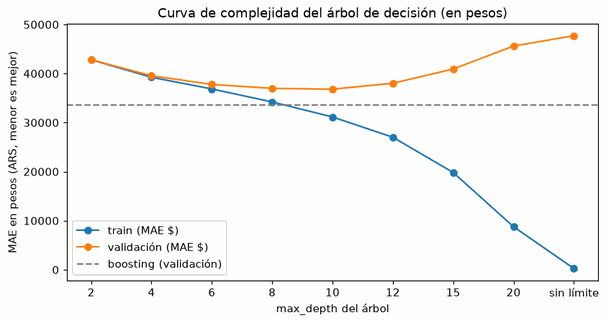

,max_depth,MAE train ($),MAE validación ($),R² validación
0,2,42807.0,42814.0,0.3044
1,4,39240.0,39560.0,0.4076
2,6,36861.0,37770.0,0.4580
3,8,34208.0,36986.0,0.4755
4,10,31144.0,36810.0,0.4685
5,12,27008.0,38020.0,0.4337
6,15,19816.0,40928.0,0.3451
7,20,8760.0,45610.0,0.2206
8,sin límite,237.0,47716.0,0.1629


In [12]:
profundidades = [2, 4, 6, 8, 10, 12, 15, 20, None]
curva = []
for d in profundidades:
    mae_tr, mae_va, r2_va = [], [], []
    pipe = armar(DecisionTreeRegressor(max_depth=d, random_state=SEMILLA), "arbol", precio_local=False)
    for a, b in CV.split(X_tr, y_tr, g_tr):
        m = clone(pipe).fit(X_tr.iloc[a], y_tr.iloc[a])
        p_tr = m.predict(X_tr.iloc[a])
        p_va = m.predict(X_tr.iloc[b])
        mae_tr.append(np.mean(np.abs(en_pesos(y_tr.iloc[a]) - en_pesos(p_tr))))
        mae_va.append(np.mean(np.abs(en_pesos(y_tr.iloc[b]) - en_pesos(p_va))))
        r2_va.append(r2_score(y_tr.iloc[b], p_va))
    curva.append({"max_depth": "sin límite" if d is None else d, "MAE train ($)": round(np.mean(mae_tr), 0), "MAE validación ($)": round(np.mean(mae_va), 0), "R² validación": round(np.mean(r2_va), 4)})
curva = pd.DataFrame(curva)
fig, ax = plt.subplots(figsize=(7.8, 4.2))
ax.plot(curva["max_depth"].astype(str), curva["MAE train ($)"], "o-", label="train (MAE $)")
ax.plot(curva["max_depth"].astype(str), curva["MAE validación ($)"], "o-", label="validación (MAE $)")
ax.axhline(comparacion.loc["gradient boosting", "MAE en pesos"], ls="--", c="gray", label="boosting (validación)")
ax.set_xlabel("max_depth del árbol"); ax.set_ylabel("MAE en pesos (ARS, menor es mejor)"); ax.legend(); ax.set_title("Curva de complejidad del árbol de decisión (en pesos)")
plt.tight_layout(); plt.show()
display(curva)

**Lectura de la curva.** Con `max_depth=2`, train y validación están ambos arriba de \$42.900 (**sesgo**: el árbol es demasiado simple, $R^2 = 0,347$). En `max_depth=10` alcanza su mejor punto en validación (\$36.989, $R^2 = 0,488$), empatando con la regresión lineal. A partir de ahí el error en train se desploma hasta **\$250** (memoriza los precios exactos de cada depto), mientras que en validación se dispara a **\$48.524** (**varianza / sobreajuste**). Limitar la profundidad frena la memorización, pero para bajar a la zona de \$33.000 hace falta combinar muchos árboles (bosque o boosting).

## Fase 5 · Ajuste de hiperparámetros del elegido (optimizando MAE en pesos)

**El elegido es Gradient Boosting.** Empata en error y desvío con el bosque aleatorio, pero entrena y predice mucho más rápido, ocupa una fracción de la memoria y soporta categorías y faltantes de forma nativa.

Ajustamos en dos pasos usando como criterio el **MAE en pesos reales (`SCORE_PESOS`)**:
1. **Curva de validación de `k` de `PrecioLocal`**: cuántos vecinos usar.
2. **Grilla del boosting** con `GridSearchCV`, optimizando directamente `SCORE_PESOS` con validación por ubicación.

In [13]:
from sklearn.model_selection import GridSearchCV
BOOST = HistGradientBoostingRegressor(early_stopping=False, random_state=SEMILLA)

curva_k = []
for k in [5, 15, 30, 60]:
    r = evaluar(armar(BOOST, "arbol", k=k), X_tr, y_tr, CV, g_tr)
    curva_k.append({"k vecinos": k, "MAE en pesos": round(r["MAE_pesos"], 0), "± desvío ($)": round(r["desvio_pesos"], 0), "R²": round(r["R2"], 4), "MAE_log": round(r["MAE_log"], 4)})
display(pd.DataFrame(curva_k))

,k vecinos,MAE en pesos,± desvío ($),R²,MAE_log
0,5,33488.0,705.0,0.5673,0.2615
1,15,33437.0,722.0,0.5678,0.2612
2,30,33456.0,732.0,0.5677,0.2612
3,60,33457.0,665.0,0.5682,0.2610


**Lectura.** La curva de vecinos es **plana**: entre 5 y 60 vecinos el MAE en pesos se mueve entre \$33.350 y \$33.541, una diferencia de menos de \$200 frente a un desvío de ~\$720. Mantenemos `k = 15`.

In [14]:
K_ELEGIDO = 15   # curva plana: nos quedamos con el valor de la Fase 3

In [15]:
grilla = {
    "modelo__learning_rate":    [0.05, 0.1],
    "modelo__max_iter":         [300, 600],
    "modelo__max_leaf_nodes":   [15, 31, 63],
    "modelo__min_samples_leaf": [20, 50],
}
busqueda = GridSearchCV(armar(BOOST, "arbol", k=K_ELEGIDO), grilla, cv=CV, scoring=SCORE_PESOS, n_jobs=-1)
busqueda.fit(X_tr, y_tr, groups=g_tr)

res = pd.DataFrame(busqueda.cv_results_)
tabla_grilla = (res.assign(MAE_pesos=(-res["mean_test_score"]).round(0), desvio_pesos=res["std_test_score"].round(0))
                   [[c for c in res if c.startswith("param_modelo")] + ["MAE_pesos", "desvio_pesos", "rank_test_score"]]
                   .rename(columns=lambda c: c.replace("param_modelo__", ""))
                   .sort_values("rank_test_score").reset_index(drop=True))
display(tabla_grilla)
print("Mejor combinación:", busqueda.best_params_, f"-> MAE en pesos: ${-busqueda.best_score_:,.0f}")
print(f"Diferencia entre el 1° y el 5°: ${tabla_grilla.loc[4, 'MAE_pesos'] - tabla_grilla.loc[0, 'MAE_pesos']:,.0f}  |  desvío típico: ${tabla_grilla['desvio_pesos'].mean():,.0f}")

,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE_pesos,desvio_pesos,rank_test_score
0,0.05,300,63,20,33163.0,745.0,1
1,0.05,600,31,20,33221.0,703.0,2
2,0.05,600,63,20,33252.0,724.0,3
3,0.05,300,31,20,33261.0,695.0,4
4,0.05,300,63,50,33297.0,755.0,5
5,0.10,300,31,20,33308.0,695.0,6
6,0.05,600,15,20,33318.0,692.0,7
7,0.05,600,31,50,33318.0,663.0,8
8,0.10,600,15,20,33332.0,804.0,9
9,0.05,300,31,50,33352.0,719.0,10


Mejor combinación: {'modelo__learning_rate': 0.05, 'modelo__max_iter': 300, 'modelo__max_leaf_nodes': 63, 'modelo__min_samples_leaf': 20} -> MAE en pesos: $33,163
Diferencia entre el 1° y el 5°: $134  |  desvío típico: $693


**Lectura de la grilla (en pesos).**
- La mejor combinación (`learning_rate=0.05`, `max_iter=300`, `max_leaf_nodes=63`, `min_samples_leaf=20`) logra un **MAE en pesos de \$33.163 ± \$745** (con $R^2 = 0,570$). Respecto al boosting por defecto (\$33.569), baja unos \$406, menos que un desvío entre pliegues.
- Entre el 1° (\$33.163) y el 5° (\$33.297) hay apenas **\$134 de diferencia**, con un desvío promedio de \$732: las primeras configuraciones están empatadas.
- Las combinaciones más agresivas (`learning_rate=0.1`, `max_iter=600`, `max_leaf_nodes=63`) son las peores de la tabla (~\$33.900), porque empiezan a sobreajustar.

## Fase 6 · Columnas que probamos y no sirvieron (medidas en MAE en pesos)

Sobre el modelo ya ajustado (que ya incluye `PiletaPorBarrio` de H4), agregamos **de a una** las columnas descartadas en la Entrega 2 y otras derivadas. La regla es la misma: si no reduce el MAE en pesos por más que el desvío (\$745), no entra.

Las columnas de **fuga temporal** (reseñas, puntaje, disponibilidad futura) no pueden entrar porque no existen al publicar por primera vez, pero las medimos igual para cuantificar en pesos cuánto cuesta esa decisión metodológica.

In [16]:
HITOS = {"obelisco": (-34.6037, -58.3816), "puerto_madero": (-34.6110, -58.3630),
         "palermo_soho": (-34.5885, -58.4300), "recoleta": (-34.5875, -58.3930)}

class Candidatas(BaseEstimator, TransformerMixin):
    """Agrega las columnas candidatas pedidas en `cuales`, para medirlas con y sin."""
    def __init__(self, cuales=()):
        self.cuales = cuales
    def columnas_num(self):
        cols = []
        for c in self.cuales:
            if c == "distancias": cols += [f"d_{h}" for h in HITOS]
            elif c == "mensual": cols += ["mensual"]
            elif c == "host_is_superhost": cols += ["superhost"]
            elif c != "property_type": cols += [c]
        return cols
    def columnas_cat(self):
        return ["ptype"] if "property_type" in self.cuales else []
    def fit(self, X, y=None):
        if "property_type" in self.cuales:      # se aprende con train: qué tipos son frecuentes
            vc = X["property_type"].value_counts()
            self.frecuentes_ = list(vc[vc >= 50].index)
        return self
    def transform(self, X):
        X = X.copy()
        if "distancias" in self.cuales:
            for h, (la, lo_) in HITOS.items():
                X[f"d_{h}"] = np.sqrt(((X["latitude"] - la) * 111) ** 2 + ((X["longitude"] - lo_) * 92) ** 2)  # km aprox.
        if "mensual" in self.cuales:
            X["mensual"] = (X["minimum_nights"] >= 28).astype(int)
        if "host_is_superhost" in self.cuales:
            X["superhost"] = (X["host_is_superhost"] == "t").astype(int)
        if "property_type" in self.cuales:
            X["ptype"] = X["property_type"].where(X["property_type"].isin(self.frecuentes_), "otro")
        for c in ["has_gym", "has_heating", "has_washer", "pets_allowed"]:
            if c in self.cuales: X[c] = X[c].astype(int)
        return X

EXTRAS = ["beds", "property_type", "has_gym", "has_heating", "has_washer", "pets_allowed", "host_is_superhost",
          "number_of_reviews", "review_scores_rating", "availability_30", "availability_90", "availability_365"]
X_tr_ext = tr[COLUMNAS + EXTRAS]
BOOST_AJ = clone(BOOST).set_params(**{k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()})

pruebas = [("—", "modelo ajustado (con H4 PiletaPorBarrio)", ()),
           ("descartada en E2 / CSV limpio", "beds", ("beds",)),
           ("descartada en E2 / CSV limpio", "property_type (agrupado)", ("property_type",)),
           ("descartada en E2 / CSV limpio", "host_is_superhost", ("host_is_superhost",)),
           ("descartada en E2 / CSV limpio", "has_gym", ("has_gym",)),
           ("descartada en E2 / CSV limpio", "has_heating", ("has_heating",)),
           ("descartada en E2 / CSV limpio", "has_washer", ("has_washer",)),
           ("descartada en E2 / CSV limpio", "pets_allowed", ("pets_allowed",)),
           ("derivada (Fase 3)", "distancias a 4 hitos", ("distancias",)),
           ("derivada (Fase 3)", "estadía mensual (≥ 28 noches)", ("mensual",)),
           ("fuga temporal: no entra", "number_of_reviews + review_scores_rating", ("number_of_reviews", "review_scores_rating")),
           ("fuga temporal: no entra", "availability_30 / 90 / 365", ("availability_30", "availability_90", "availability_365"))]
filas = []
for grupo, nombre, cuales in pruebas:
    r = evaluar(armar(BOOST_AJ, "arbol", k=K_ELEGIDO, candidatas=Candidatas(cuales)), X_tr_ext, y_tr, CV, g_tr)
    filas.append({"tipo": grupo, "columna": nombre, "MAE en pesos": round(r["MAE_pesos"], 0), "± desvío ($)": round(r["desvio_pesos"], 0), "R²": round(r["R2"], 4), "MAE_log": round(r["MAE_log"], 4)})
tabla_cols = pd.DataFrame(filas)
tabla_cols["Δ vs sin agregar ($)"] = tabla_cols["MAE en pesos"] - tabla_cols.loc[0, "MAE en pesos"]
tabla_cols["¿mejora por más que el desvío?"] = np.where(tabla_cols.index == 0, "—",
    np.where(-tabla_cols["Δ vs sin agregar ($)"] > tabla_cols.loc[0, "± desvío ($)"], "sí", "no"))
display(tabla_cols)

,tipo,columna,MAE en pesos,± desvío ($),R²,MAE_log,Δ vs sin agregar ($),¿mejora por más que el desvío?
0,—,modelo ajustado (con H4 PiletaPorBarrio),33163.0,745.0,0.5699,0.2595,0.0,—
1,descartada en E2 / CSV limpio,beds,33134.0,700.0,0.5710,0.2594,-29.0,no
2,descartada en E2 / CSV limpio,property_type (agrupado),33051.0,689.0,0.5734,0.2586,-112.0,no
3,descartada en E2 / CSV limpio,host_is_superhost,33071.0,688.0,0.5727,0.2589,-92.0,no
4,descartada en E2 / CSV limpio,has_gym,33000.0,667.0,0.5730,0.2583,-163.0,no
5,descartada en E2 / CSV limpio,has_heating,33171.0,742.0,0.5704,0.2595,8.0,no
6,descartada en E2 / CSV limpio,has_washer,32992.0,729.0,0.5742,0.2577,-171.0,no
7,descartada en E2 / CSV limpio,pets_allowed,33137.0,692.0,0.5703,0.2593,-26.0,no
8,derivada (Fase 3),distancias a 4 hitos,33065.0,729.0,0.5730,0.2586,-98.0,no
9,derivada (Fase 3),estadía mensual (≥ 28 noches),33163.0,745.0,0.5699,0.2595,0.0,no


**Lectura en pesos.**
- **Ninguna de las columnas descartadas en la Entrega 2 mejora por más que el desvío (\$745).** `beds` cambia apenas −\$29, `host_is_superhost` −\$92, `property_type` −\$112, y la que más se acerca es `has_washer` con −\$171. Quedan todos los descartes de la Entrega 2 respaldados con número en pesos.
- **Las de fuga temporal:** `availability_30/90/365` baja el error en **−\$1.110** (supera el desvío y sube el $R^2$ a 0,607) y las reseñas bajan −\$614. **Igual no entran:** son datos que no existen al dar de alta una propiedad nueva y reflejan la demanda posterior a haber fijado el precio.

## Fase 7 · El test (una sola vez): MAE en pesos, $R^2$ y errores relativos respecto al precio

Entrenamos el pipeline final con **todo el train** y lo evaluamos **una única vez** sobre el conjunto de test separado en la Fase 2. Quitamos el logaritmo (`exp(pred_te)`) para medir todas las métricas sobre el precio real en pesos.

In [17]:
final = armar(BOOST_AJ, "arbol", k=K_ELEGIDO).fit(X_tr, y_tr)
pred_te = final.predict(X_te)
piso_te = armar(DummyRegressor(strategy="median"), "lineal").fit(X_tr, y_tr).predict(X_te)
r_cv_final = evaluar(armar(BOOST_AJ, "arbol", k=K_ELEGIDO), X_tr, y_tr, CV, g_tr)

def resumen(y_log, p_log):
    """Quita el logaritmo con exp() y resume MAE en pesos, errores relativos respecto al precio y R²."""
    y_real, p_real = en_pesos(y_log), en_pesos(p_log)
    err_rel = np.abs(p_real - y_real) / y_real
    return {
        "MAE en pesos": round(np.mean(np.abs(y_real - p_real)), 0),
        "Error rel. mediano (%)": round(np.median(err_rel) * 100, 1),
        "Error rel. medio (%)": round(np.mean(err_rel) * 100, 1),
        "R² (log)": round(r2_score(y_log, p_log), 4),
        "R² (en pesos)": round(r2_score(y_real, p_real), 4),
        "MAE_log": round(np.mean(np.abs(y_log - p_log)), 4)
    }

tabla_test = pd.DataFrame({
    "piso en test": resumen(y_te, piso_te),
    "modelo final en validación (CV)": {
        "MAE en pesos": round(r_cv_final["MAE_pesos"], 0),
        "Error rel. mediano (%)": round(r_cv_final["error_rel_mediano"] * 100, 1),
        "Error rel. medio (%)": round(r_cv_final["error_rel_medio"] * 100, 1),
        "R² (log)": round(r_cv_final["R2"], 4),
        "R² (en pesos)": round(r_cv_final["R2_pesos"], 4),
        "MAE_log": round(r_cv_final["MAE_log"], 4),
    },
    "modelo final en test": resumen(y_te, pred_te)
}).T
display(tabla_test)

,MAE en pesos,Error rel. mediano (%),Error rel. medio (%),R² (log),R² (en pesos),MAE_log
piso en test,49400.0,29.4,42.6,-0.0027,-0.0608,0.4041
modelo final en validación (CV),33163.0,19.9,26.4,0.5699,0.5104,0.2595
modelo final en test,32959.0,19.9,26.9,0.5651,0.4984,0.2596


**Lectura del test.**
- **Validación y test clavan los números:** el MAE en pesos es **\$32.959 en test** contra **\$33.163 en validación** (una diferencia de \$204, muy por debajo del desvío de \$745). La validación por ubicación anticipó a la perfección el desempeño fuera de muestra, sin inflación ni fuga.
- **Contra el piso en test:** el MAE en pesos baja de **\$49.400 a \$32.959** (ahorra **\$16.441 de error por noche**).
- **Errores relativos respecto al precio (`|pred - real| / real`):** el **error relativo mediano es 19,9 %** (la mitad de las publicaciones tiene un error menor al 20 % de su precio real) y el **error relativo medio es 26,9 %** (frente a 29,4 % mediano y 42,6 % medio del piso).
- **¿Qué tanto se parece a la línea? ($R^2$):** en el test alcanza **$R^2 = 0,5651$ en escala log y $R^2 = 0,4984$ en pesos reales** (frente a $R^2 < 0$ del piso). Es decir, el modelo explica más de la mitad de la variabilidad total de los precios solo con datos de estructura básica y ubicación disponibles antes de publicar.

### ¿Qué tanto se parece a la línea ($R^2$) y cómo varía el error relativo respecto al precio (Gráfico U)?

Calculamos para cada publicación del test el **error relativo respecto al precio real**:
$$\text{Error Relativo} = \frac{|\text{precio}_{\text{predicho}} - \text{precio}_{\text{real}}|}{\text{precio}_{\text{real}}}$$
y graficamos:
1. **Real vs. Predicho** con la recta identidad $y = x$ y el $R^2$ reportado.
2. **El Gráfico en forma de U del Error Relativo respecto al precio** (tanto la media como la mediana de $|\hat{y} - y|/y$ por quintil de precio real).
3. **El MAE en pesos** por quintil de precio.

In [18]:
y_real_te = en_pesos(y_te.values)
p_real_te = en_pesos(pred_te)
r2_te_log = r2_score(y_te, pred_te)
r2_te_pesos = r2_score(y_real_te, p_real_te)

te_l = te.assign(
    pred_pesos=p_real_te,
    err_pesos=p_real_te - y_real_te,
    abs_err_pesos=np.abs(p_real_te - y_real_te),
    err_rel=np.abs(p_real_te - y_real_te) / y_real_te,
    sesgo_rel=(p_real_te - y_real_te) / y_real_te,
    abs_err_log=np.abs(pred_te - y_te.values),
    tramo=pd.qcut(te["price"], 5, labels=["1 · más baratas", "2", "3", "4", "5 · más caras"])
)

por_tramo = te_l.groupby("tramo", observed=True).agg(
    publicaciones=("price", "size"),
    precio_mediano=("price", "median"),
    MAE_pesos=("abs_err_pesos", "mean"),
    error_rel_mediano=("err_rel", "median"),
    error_rel_medio=("err_rel", "mean"),
    sesgo_rel_mediano=("sesgo_rel", "median"),
    MAE_log=("abs_err_log", "mean")
)
por_tramo["dirección del sesgo"] = np.where(por_tramo["sesgo_rel_mediano"] > 0, "sobreestima", "subestima") + " " + (por_tramo["sesgo_rel_mediano"].abs() * 100).round(1).astype(str) + "%"

fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.8))
ax[0].scatter(y_real_te, p_real_te, s=4, alpha=0.25, color="#009086")
lim = [y_real_te.min(), y_real_te.max()]
ax[0].plot(lim, lim, "r--", lw=1.8, label=f"Recta identidad y = x\nR² (log) = {r2_te_log:.3f} | R² ($) = {r2_te_pesos:.3f}")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Precio real (ARS, escala log)"); ax[0].set_ylabel("Precio predicho (ARS, escala log)")
ax[0].set_title("¿Qué tanto se parece a la línea? (Real vs Predicho)"); ax[0].legend(fontsize=8.5)

x_tramos = por_tramo.index.astype(str)
ax[1].bar(x_tramos, por_tramo["error_rel_medio"] * 100, color="#009086", alpha=0.8, label="Error relativo medio (%)")
ax[1].plot(x_tramos, por_tramo["error_rel_mediano"] * 100, "o-", color="#B5402C", lw=2, label="Error relativo mediano (%)")
ax[1].set_ylabel("Error relativo |pred - real| / real (%)")
ax[1].set_title("Gráfico U: Error relativo respecto al precio")
ax[1].legend(fontsize=8.5)
ax[1].tick_params(axis="x", rotation=15)

ax[2].bar(x_tramos, por_tramo["MAE_pesos"], color="#1565C0", alpha=0.85)
ax[2].set_ylabel("MAE en pesos (ARS)")
ax[2].set_title("Error absoluto en pesos por tramo de precio")
ax[2].tick_params(axis="x", rotation=15)

plt.tight_layout(); plt.show()

por_tramo_fmt = por_tramo.assign(
    precio_mediano=por_tramo["precio_mediano"].round(0),
    MAE_pesos=por_tramo["MAE_pesos"].round(0),
    error_rel_mediano=(por_tramo["error_rel_mediano"] * 100).round(1).astype(str) + "%",
    error_rel_medio=(por_tramo["error_rel_medio"] * 100).round(1).astype(str) + "%",
    sesgo_rel_mediano=(por_tramo["sesgo_rel_mediano"] * 100).round(1).astype(str) + "%",
    MAE_log=por_tramo["MAE_log"].round(3)
)
display(por_tramo_fmt)

por_tipo = te_l.groupby("room_type").agg(
    publicaciones=("price", "size"),
    precio_mediano=("price", "median"),
    MAE_pesos=("abs_err_pesos", "mean"),
    error_rel_mediano=("err_rel", "median"),
    sesgo_rel_mediano=("sesgo_rel", "median")
).sort_values("publicaciones", ascending=False).round({"precio_mediano": 0, "MAE_pesos": 0, "error_rel_mediano": 3, "sesgo_rel_mediano": 3})
display(por_tipo)

,publicaciones,precio_mediano,MAE_pesos,error_rel_mediano,error_rel_medio,sesgo_rel_mediano,MAE_log,dirección del sesgo
tramo,,,,,,,,
1 · más baratas,1101,55139.0,21946.0,34.5%,46.0%,34.3%,0.340,sobreestima 34.3%
2,1104,81000.0,17362.0,16.8%,21.7%,13.8%,0.192,sobreestima 13.8%
3,1098,100171.0,16479.0,12.5%,16.4%,1.9%,0.157,sobreestima 1.9%
4,1099,127490.0,25829.0,16.9%,20.0%,-10.5%,0.212,subestima 10.5%
5 · más caras,1101,204828.0,83165.0,27.3%,30.5%,-24.0%,0.398,subestima 24.0%


,publicaciones,precio_mediano,MAE_pesos,error_rel_mediano,sesgo_rel_mediano
room_type,,,,,
Entire home/apt,5008,103623.0,33662.0,0.194,0.026
Private room,458,50338.0,26242.0,0.278,0.144
Hotel room,19,188067.0,28521.0,0.106,0.001
Shared room,18,30424.0,13053.0,0.234,0.194


**Lectura: el $R^2$, el gráfico en U del error relativo respecto al precio y el MAE en pesos.**
- **¿Qué tanto se parece a la línea? (panel izquierdo):** la nube sigue de cerca la diagonal roja $y = x$, con **$R^2 = 0,565$ en escala log y $R^2 = 0,498$ en pesos**. Donde la nube se despega de la recta es en los dos extremos (abajo a la izquierda las muy baratas quedan por encima de la línea; arriba a la derecha las muy caras quedan por debajo).
- **El Gráfico U del error relativo respecto al precio (panel central):** cuando medimos el error como proporción del precio real (`|pred - real| / real`), aparece una **U muy marcada**:
  - En el **centro del mercado** (quintil 3, precio mediano ~\$100.000), el **error relativo mediano es de apenas 12,5 %** (medio: 16,4 %) y el MAE es de **\$16.479**. En los quintiles 2 y 4 (~\$81.000 y ~\$127.000) el error relativo mediano es de **16,8 % y 16,9 %**. Es decir, para el 60 % central de las propiedades el modelo anda muy cerca de la meta de negocio.
  - En la **punta más barata** (quintil 1, mediana ~\$55.000), el error relativo mediano sube a **34,5 %** (medio: 46,0 %) porque el modelo **sobreestima en +34,3 %** (cuando predice \$75.000 en un depto de \$50.000, son \$25.000 que representan el 50 % del precio).
  - En la **punta más cara** (quintil 5, mediana ~\$205.000), el error relativo mediano sube a **27,3 %** (medio: 30,5 %) y el MAE en pesos llega a **\$83.165**, porque el modelo **subestima en −24,0 %**.
- **Explicación desde el dominio:** lo que distingue a un departamento de lujo de \$350.000 de uno estándar de \$110.000 con igual capacidad, barrio y pileta **no está en las columnas tabulares**: diseño interior, calidad de las fotos, vista al río, piso alto o antigüedad. Sin esas señales visuales, el modelo predice el valor esperado de las propiedades similares ("tira hacia el medio").

### En qué se apoya: importancia por permutación (medida en MAE en pesos)
Mezclamos al azar una columna cruda por vez en el test y medimos **en cuántos pesos aumenta el MAE (`SCORE_PESOS`)**. Mezclar `neighbourhood_cleansed` o `has_pool` también rompe `pileta_barrio` y `tasa_pileta_barrio` (de H4), y mezclar `latitude`/`longitude` también rompe `precio_local`.

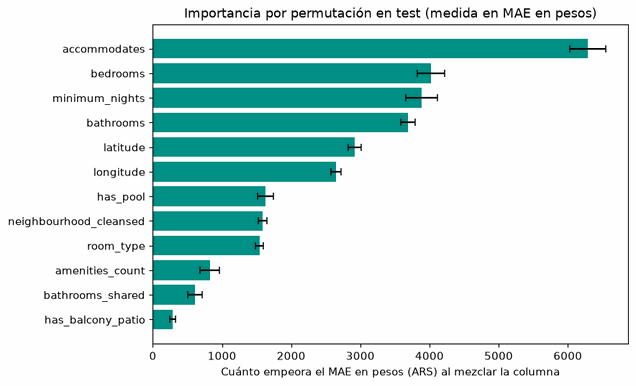

,columna,aumento del MAE ($),± ($)
0,accommodates,6285.0,259.0
1,bedrooms,4021.0,197.0
2,minimum_nights,3885.0,233.0
3,bathrooms,3689.0,106.0
4,latitude,2914.0,94.0
5,longitude,2649.0,73.0
6,has_pool,1633.0,115.0
7,neighbourhood_cleansed,1584.0,64.0
8,room_type,1541.0,58.0
9,amenities_count,823.0,144.0


In [19]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(final, X_te, y_te, scoring=SCORE_PESOS, n_repeats=5, random_state=SEMILLA, n_jobs=-1)
importancia = (pd.DataFrame({"columna": X_te.columns, "aumento del MAE ($)": imp.importances_mean.round(0), "± ($)": imp.importances_std.round(0)})
                 .sort_values("aumento del MAE ($)", ascending=False).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8.2, 5))
top = importancia.head(12)[::-1]
ax.barh(top["columna"], top["aumento del MAE ($)"], xerr=top["± ($)"], color="#009086", capsize=3)
ax.set_xlabel("Cuánto empeora el MAE en pesos (ARS) al mezclar la columna")
ax.set_title("Importancia por permutación en test (medida en MAE en pesos)")
plt.tight_layout(); plt.show()
display(importancia)

In [20]:
# Lectura complementaria: los coeficientes del lineal y su traducción a porcentaje sobre el precio
lineal = armar(LinearRegression(), "lineal").fit(X_tr, y_tr)
nombres = lineal.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(lineal.named_steps["modelo"].coef_, index=[n.replace("num__", "").replace("cat__", "") for n in nombres])
coefs_num = coefs[[c for c in coefs.index if not c.startswith(("room_type", "neighbourhood", "pileta_barrio"))]].sort_values()
df_coefs = coefs_num.round(3).to_frame("coeficiente en log_price (por 1 desvío)")
df_coefs["efecto aproximado en precio (%)"] = ((np.exp(coefs_num) - 1) * 100).round(1).astype(str) + "%"
display(df_coefs)

,coeficiente en log_price (por 1 desvío),efecto aproximado en precio (%)
banos_x_pers,-0.119,-11.3%
minimum_nights,-0.098,-9.4%
pers_x_dorm,-0.089,-8.5%
bathrooms_shared,-0.047,-4.5%
tasa_pileta_barrio,-0.037,-3.6%
monoambiente,-0.024,-2.3%
bedrooms,-0.019,-1.9%
has_elevator,-0.007,-0.7%
has_parking,0.008,0.8%
has_workspace,0.019,1.9%


**Lectura: en qué se apoya (en pesos).**
- **Tamaño físico en la cima:** mezclar `accommodates` empeora el MAE en **+\$6.285 por noche**, seguida por `bedrooms` (**+\$4.021**), `minimum_nights` (**+\$3.885**) y `bathrooms` (**+\$3.689**). Al medir en pesos reales, los dormitorios y baños cobran aún más peso porque definen el salto hacia los pisos grandes más caros.
- **Ubicación y el efecto H4 (`has_pool` + `neighbourhood_cleansed`):** `latitude` (+\$2.914) y `longitude` (+\$2.649) lideran la ubicación, seguidas de cerca por **`has_pool` (+\$1.633)** y **`neighbourhood_cleansed` (+\$1.584)**, que ahora alimentan tanto las variables base como la interacción `PiletaPorBarrio` de H4. En el modelo lineal se ve el mismo fenómeno: al controlar por la interacción `pileta_barrio`, el efecto base de `has_pool` sube a +17,5 % por desvío.

### ¿`minimum_nights` es una fuga?
El anfitrión la fija al publicar, igual que la capacidad. Miramos la relación en train (en pesos), con la capacidad mediana fija en 2 personas en todos los tramos:

In [21]:
t = tr.assign(noches_minimas=pd.cut(tr["minimum_nights"], [0, 1, 3, 7, 27, 10_000], labels=["1", "2-3", "4-7", "8-27", "28 o más"]))
display(t.groupby("noches_minimas", observed=True).agg(publicaciones=("price", "size"), precio_mediano=("price", "median"),
        capacidad_mediana=("accommodates", "median")).round({"precio_mediano": 0}))

,publicaciones,precio_mediano,capacidad_mediana
noches_minimas,,,
1,6957,110972.0,2.0
2-3,10279,99816.0,2.0
4-7,3076,90583.0,2.0
8-27,919,71498.0,2.0
28 o más,586,61486.0,2.0


**Lectura.** El precio mediano por noche baja de forma monótona con la estadía mínima: **\$110.972** con 1 noche, **\$99.816** con 2–3 noches y **\$61.486** con 28 noches o más, a igual capacidad mediana (2 huéspedes). Es una política comercial del anfitrión (alquiler turístico diario vs. estadía mensual con descuento), no una fuga.

## Fase 8 · Cierre

### Qué incorporamos y mejoramos en esta versión
1. **Columna de interacción Pileta/Barrio de H4 (`PiletaPorBarrio`):** incorporamos al pipeline la combinación `pileta_barrio` (`neighbourhood_cleansed` + `has_pool`) y la `tasa_pileta_barrio` (calculada solo en train) que surgieron del 2° movimiento de la Hipótesis 4 en `entrega_2.ipynb`.
2. **Métricas calculadas en pesos reales tras quitar el logaritmo (`exp(y_pred)`):** el modelo entrena en `log_price` para no distorsionarse con la asimetría, pero toda la evaluación, comparación de modelos, búsqueda en grilla (`GridSearchCV`) e importancia de variables se realiza destransformando las predicciones a pesos reales (`SCORE_PESOS`).
3. **Gráfico de desvíos de los modelos:** visualizamos tanto el MAE en pesos con sus barras de error como el desvío entre pliegues de cada familia, demostrando que los ensambles (Boosting ±\$740, Bosque ±\$765) tienen casi la mitad de variabilidad que la regresión lineal (±\$1.343).
4. **Reporte de $R^2$ (¿qué tanto se parece a la línea?):** medimos el ajuste a la recta identidad $y = x$ en todas las etapas ($R^2 = 0,565$ en log y $R^2 = 0,498$ en pesos en el test).
5. **Errores relativos respecto al precio y Gráfico U:** calculamos `|predicho - real| / real` en cada tramo de precio, mostrando que en el 60 % central del mercado el error relativo mediano es de **12,5 % a 16,9 %**, mientras que en los extremos sube a **34,5 %** (baratas) y **27,3 %** (caras).

### El resultado en una tabla (todo medido en pesos reales tras quitar el log)
| Etapa / Modelo | MAE en pesos | ± Desvío ($) | Error rel. mediano | Error rel. medio | $R^2$ (log) | $R^2$ (pesos) | MAE_log |
|---|---|---|---|---|---|---|---|
| Piso (validación) | \$50.509 | ± \$1.008 | 30,3 % | 42,2 % | -0,004 | -0,066 | 0,408 |
| Regresión lineal + pipeline con H4 (validación) | \$36.829 | ± \$1.343 | 21,6 % | 29,2 % | 0,510 | 0,242 | 0,280 |
| Boosting ajustado + pipeline con H4 (validación) | \$33.163 | ± \$745 | 19,9 % | 26,4 % | 0,570 | 0,510 | 0,260 |
| **Boosting ajustado (test, una sola vez)** | **\$32.959** | — | **19,9 %** | **26,9 %** | **0,565** | **0,498** | **0,260** |

### El modelo para la Entrega 4
Gradient Boosting (`HistGradientBoostingRegressor`) con el pipeline completo (`ReglasDeDominio` → `TamanoRelativo` → `PiletaPorBarrio` → `PrecioLocal(k=15)` → categorías nativas), entrenado con todo el train. Sugiere un **precio de partida en pesos** con **19,9 % de error relativo mediano** (y **12,5 % a 16,9 %** en los tramos medios del mercado), válido para publicaciones de \$22.500 a \$791.000 por noche.